# GridWorld

Classic example introduced in Sutton & Barto's book (*Reinforcement Learning: An Introduction*).

In this notebook, the GridWorld problem is modeled as a Markov Decision Process (MDP). We apply dynamic programming using the Bellman Expectation Equation under an equiprobable random policy to compute the state-value function $V(s)$ and extract the greedy path from start to goal.


In [1]:
# Libraries
import matplotlib.pyplot as plt
import numpy as np


## Grid Creation

The environment is represented by a 2D matrix of dimensions $x \times y$ initialized to zeros using NumPy:
- **Initial state (`ini`)**: Marked with value `-1` (rendered in white).
- **Goal state (`goal`)**: Marked with value `4` (rendered in dark gray).

The `stepGrid` method handles transitions: if a proposed action exceeds the grid boundaries, the agent remains in its previous state. The `plotGrid` method displays the grid using `imshow` with `cmap="gray_r"`, positioning minor ticks at $-0.5$ offsets to draw explicit cell borders and overlaying numerical state values at the center of each cell.


In [2]:
class gridWorld:

    def __init__(self, x, y, ini, goal):
        self.x, self.y = x, y
        self.grid = np.zeros((x, y)) # we create the grid with the desired size
        self.grid[ini] = -1
        self.grid[goal] = 4
        self.start = ini
        self.prev_state = ini
    

    def stepGrid(self, state, action):
        # check that it does not go out of the grid
        new_x = state[0] + action[0]
        new_y = state[1] + action[1]
        self.prev_state = state

        if new_x >= self.x or new_x < 0 or new_y >= self.y or new_y < 0:
            next_state = self.prev_state # if it exceeds grid boundaries or is equal, it is an invalid move, same for zero
            # so we revert to the previous state
        else:
            next_state = (new_x, new_y) # otherwise we advance state to the next one
        

        # Paint the cell
        #if self.prev_state != self.start: # check the initial state
            #self.grid[self.prev_state] = 0 # paint base gray color
        #else:
            #self.grid[self.prev_state] = -1 # white color if previous cell is start to indicate where we started

        #self.grid[state] = 1 # paint dark gray to indicate where we are right now
        
        
        return next_state

        
    def plotGrid(self, states):
        fig, ax = plt.subplots()  # we use subplots because it is easier to work with them, here canvas size is default


        '''
        cmap 

        5 = black color
        -1 = white color
        '''
        im = ax.imshow(self.grid, cmap="gray_r", vmin=-1, vmax=5, origin="upper")
        #fig # in a jupyter notebook leaving fig at the end calls plt.show()
        ax.set_title("GridWorld")

        # Ticks to center and grid
        ax.set_xticks([]) # remove major ticks to avoid overlap error
        ax.set_yticks([])

        # xticks horizontal axis, representing number of columns
        ax.set_xticks(np.arange(-0.5, self.y, 1), minor=True) # takes minor ticks and places them at the specified positions
        ax.set_yticks(np.arange(-0.5, self.x, 1), minor=True) 
        ax.grid(which="minor", color="black", linestyle="-", linewidth=1) # draw minor ticks as grid lines

        # Put text


        for state in states:
                ax.text(state[1], state[0], str(round(states[state], 1)), ha="center", va="center", color="black", fontsize=12) 
        return ax


# State and Action Definitions

### States
For an $N \times M$ grid ($4 \times 4$), states are discrete coordinate pairs $(r, c)$ where $r \in \{0, \dots, N-1\}$ and $c \in \{0, \dots, M-1\}$.
- **Start state**: $s_{\text{start}} = (0, 0)$ (top-left cell)
- **Goal state**: $s_{\text{goal}} = (3, 3)$ (bottom-right cell)
- **Terminal condition**: Once the agent reaches $s_{\text{goal}}$, the episode terminates and its future value is $V(s_{\text{goal}}) = 0$.

### Actions
$$\text{Actions } A = \{\text{Up } (\uparrow), \; \text{Down } (\downarrow), \; \text{Left } (\leftarrow), \; \text{Right } (\rightarrow)\}$$

### Bellman Expectation Equation
Under an equiprobable random policy where $\pi(a|s) = 0.25$, constant step penalty $r = -1$, and discount factor $\gamma = 1$:
$$V_{k+1}(s) = \sum_{a \in A} \pi(a|s) \left[ r + \gamma V_k(s') \right] = \frac{1}{4} \sum_{a \in A} \left[ -1 + \gamma V_k(s') \right]$$


{(0, 0): 0, (0, 1): 0, (0, 2): 0, (0, 3): 0, (1, 0): 0, (1, 1): 0, (1, 2): 0, (1, 3): 0, (2, 0): 0, (2, 1): 0, (2, 2): 0, (2, 3): 0, (3, 0): 0, (3, 1): 0, (3, 2): 0, (3, 3): 0}


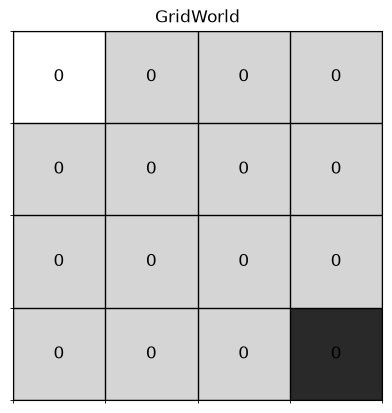

In [3]:
def get_states(x, y): # function to automatically get the number of states based on grid size
    '''
    Function to obtain possible gridworld states and total number of states.

    Being a grid, the number of states is simply rows x columns.
    It traverses the grid from left to right; once a row ends, it moves to the next.
    y count is reset and 1 is added to x.
    It cannot exceed total rows because it is bounded by the total state count.
    '''
    state = {}
    num_states = x * y
    x_init, y_init = 0, 0
    i = 0
    while i < num_states:
        # first we increment y
        state[(x_init, y_init)] = 0
        if y_init + 1 < y:
            y_init += 1
        else:
            x_init += 1
            y_init = 0
        i += 1

    return state, num_states


# =============== Initial conditions
x = 4
y = 4
states, num_states = get_states(x, y)

inicio = (0, 0)
meta = (3, 3)

grid = gridWorld(x=x, y=y, ini=inicio, goal=meta)


# ====== ACTIONS
accion = {1: (-1, 0),  # 1. Up
          2: (1, 0),   # 2. Down
          3: (0, -1),  # 3. Left
          4: (0, 1)}   # 4. Right


grid.plotGrid(states)
print(states)


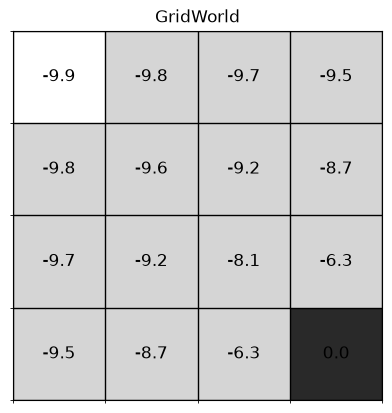

In [4]:
policy = 0.25
reco = -1
gamma = 1


k = 10
for i in range(k):
    prev_v = states.copy()
    for state in states:
        val = 0
        for acc in accion:
            next_state = grid.stepGrid(state, accion[acc])
            #print(grid.prev_state, ' and', acc, ' -> ', next_state)
            val += policy * (reco + gamma *  prev_v[next_state])

        '''
        In the book, two terminal points are considered; for that, we simply define that the values of
        those points are always zero. However, I wanted to have a designated start and a goal.
        '''
        if state == meta:  # If we only want to define a goal from the start point
       
        #if state == inicio or state == meta: # To have 2 goals as in the book
            val = 0.0

        states[state] = val

grid.plotGrid(states)


# Move the Agent from Start to Goal

> **Note**: This movement logic works with the active condition `if state == meta:`. If the commented alternative `#if state == inicio or state == meta:` is uncommented to enable two goals as in the book, this loop does not apply because the agent starts directly at one of the terminal goals (`inicio`).


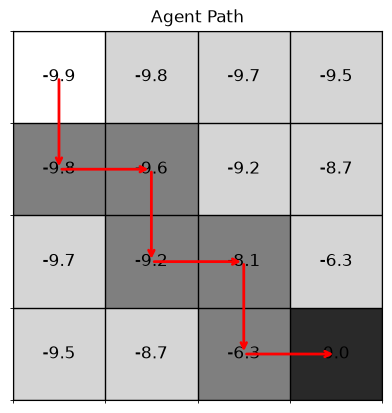

In [5]:
# ====== Greedy policy: at each cell we choose the highest reward
camino = [inicio]
estado = inicio

# Note: this works when using 'if state == meta:'. If uncommenting '#if state == inicio or state == meta:',
# this loop does not apply because 'inicio' is already a goal.
while estado != meta:
    mejor_valor = -np.inf # initialize best value to -infinity to ensure the next value is larger
    mejor_estado = estado

    for acc in accion:
        siguiente = grid.stepGrid(estado, accion[acc])   # query the next state
        if siguiente == estado:                          # if it does not move it hit a wall and we continue
            continue
        valor = states[siguiente]                        # neighbor cell value
        if valor > mejor_valor:
            mejor_valor = valor
            mejor_estado = siguiente

    estado = mejor_estado
    camino.append(estado)
    

for s in camino:
    grid.grid[s] = 2          # medium gray for the path
grid.grid[inicio] = -1        # white for start
grid.grid[meta] = 4           # dark gray for goal


# Arrows indicating movement direction (imshow uses x = column, y = row)
ax = grid.plotGrid(states)
for s, s_sig in zip(camino[:-1], camino[1:]):
    ax.annotate("", xy=(s_sig[1], s_sig[0]), xytext=(s[1], s[0]),
                arrowprops=dict(arrowstyle="->", color="red", lw=2))
ax.set_title("Agent Path")
plt.show()
